# GraphSAGE link prediction: depth check and width check

**Question.** Is the KG difference in link prediction a matter of path length? Each target's prediction
depends on a few literals that identify the answer, and a K-layer model sees only nodes within K hops of the
query head. The schemas fix how many hops away those literals are (`link_prediction_tools.evidence_hops`;
a direct property is 1 hop, a SULO path 2):

| Evidence (from the query head) | Ad-hoc | Hybrid | Pure |
|---|---|---|---|
| Team: the driver's literals (entry → driver → name, ...) | 2 | 2 | 4 |
| Position: a session's rank (entry → session → Position → rank) | 3 | 4 | 4 |
| Circuit: the race's literals (race → name, ...) | 1 | 1 | 2 |

At the main runs' K = 3 (R-GCN Pure: K = 2), this matches every R-GCN result: Team Ad-hoc 0.727 / Hybrid 0.721 /
Pure 0.267, Position 0.405 / 0.277 / 0.235, Circuit ≈ 0.93 everywhere. The LP ablation showed that Hybrid's lower
Position comes from `rank_reification` alone, the unit that adds the fourth hop. The hop table is a hypothesis
until a deeper model closes the gaps, so this notebook runs **K = 4**.

**Predictions (stated before the run):**
- **Position** stays ≈ 0.25 in every KG at both depths: GraphSAGE-mean averages a `Position` hub's single
  rank edge with ~1,000 entry edges, so no KG's GraphSAGE learned the rank at K = 3 either (LP ablation: 0.25 in all 12 graphs).
- **Pure Team** may rise at K = 4 (the driver's literals come within reach), but less than R-GCN's would,
  for the same averaging reason.
- **Ad-hoc and Hybrid** at K = 4 ≈ K = 3.

**Protocol: the LP ablation's.** Every KG gets the Hybrid winner's configuration (dim, bases, lr, wd), and only the
depth changes (`hidden_list = [dim] * (K − 1)`). Each seed in `FINAL_SEEDS` trains on the train races with early
stopping on pooled val MRR after the 50-epoch warm-up, and the best-val weights are scored on the test races, with
train + val facts as context (`run_lp_ablation_variant`). The K = 3 rows of Ad-hoc and Hybrid are the ablation's
controls, reused after checking that their configuration matches. Pure is run at K = 3 here, because its main
run used its own 2-layer winner. Pure's tuning chose 2 layers at lr 1e-2 and bases 10, where no Pure config learned
(phase-1 val MRR ≤ 0.227), so the shared-config K = 3 run also checks whether Pure's main LP result was a search
artifact. No shuffled-answer check: these are the main notebooks' graphs, checked there. Limitation: the
400-epoch cap stays (59 of 60 ablation seeds peaked in the last 50 epochs).

**Width check (GraphSAGE only).** In the main runs, GraphSAGE Hybrid scored below Ad-hoc on Team (0.329 vs 0.397)
and Circuit (0.338 vs 0.555). At the shared 64-d configuration the ablation's controls are equal (Team 0.327 vs
0.318). Ad-hoc's winner is 256-d: its phase 1 put 256-d into the verification grid ahead of 128-d by 0.0003 val
MRR, and Hybrid's verification never tried 256-d. The last section runs both KGs at Ad-hoc's winner. If they are
equal there too, the main-run gap came from the search path, not from the graphs. This notebook and
its R-GCN counterpart differ only in the encoder and the width check.

In [1]:
# Must run before CUDA is initialised: avoids fragmentation OOMs across a long sweep.
import os
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "f1_population.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from f1_node_data import load_population
from f1_population import SCHEMA_FILES, read_schema
from link_prediction.link_prediction_tools import (
    EVIDENCE_CHAINS, LP_ABLATION_METRICS, TARGETS, LinkPredictor, build_lp_data, evidence_hops, leaked_facts,
    race_split, run_lp_ablation_variant,
)
from node_prediction.gnn_tools import cleanup, limit_cuda_memory_to_free_vram, summarize_ablation
from node_prediction.models import GraphSAGEModel

MAIN_DIR = ROOT / "outputs" / "f1" / "link_prediction" / "graphsage"
ABLATION_CSV = ROOT / "outputs" / "f1" / "link_prediction" / "ablation" / "graphsage" / "ablation_results.csv"
OUT_DIR = ROOT / "outputs" / "f1" / "link_prediction" / "depth" / "graphsage"
OUT_DIR.mkdir(parents=True, exist_ok=True)
KGS = ["adhoc", "hybrid_sulo", "pure_sulo"]
print(torch.__version__, "| CUDA:", torch.cuda.is_available())
# WSL2 would otherwise overcommit VRAM into RAM and fail with a driver error instead of an OOM,
# which the run could not skip.
if torch.cuda.is_available():
    print(f"CUDA memory cap: {limit_cuda_memory_to_free_vram() / 2**30:.2f} GiB")

/home/domin/miniconda3/envs/sulo/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2.7.0+cu126 | CUDA: True
CUDA memory cap: 10.48 GiB


## Data

The three KGs exactly as in the main notebooks (`build_lp_data`, shared race split), with the leak check at both
hiding stages (training: val + test races; test: test races). The hop table is computed from the schemas.

In [2]:
entities, assertions = load_population(ROOT / "data" / "f1")
split = race_split(entities, seed=42)
schemas = {kg: read_schema(str(ROOT / path)) for kg, path in SCHEMA_FILES.items()}
lp_data = {kg: build_lp_data(kg, entities, assertions, split, schemas[kg]) for kg in KGS}
for kg, d in lp_data.items():
    for hidden in (d.race_split >= 1, d.race_split == 2):
        leaks = leaked_facts(d, hidden)
        assert set(leaks.values()) == {0}, f"{kg} leaks hidden facts: {leaks}"

pd.DataFrame({kg: {name: evidence_hops(schemas[kg], chain) for name, chain in EVIDENCE_CHAINS.items()}
              for kg in KGS}).rename_axis("hops to the evidence")

,adhoc,hybrid_sulo,pure_sulo
hops to the evidence,,,
"LP team: the driver's literals, from the entry",2,2,4
"LP team: the team's literals, from a candidate",1,1,2
"LP position: a session's rank, from the entry",3,4,4
"LP position: the rank, from a candidate",1,2,2
"LP circuit: the race's literals, from the race",1,1,2
"LP circuit: the circuit's literals, from a candidate",1,1,2
NP: the entry's own grid rank,2,3,3


## Constants

The training constants are the main notebook's (`link_prediction_graphsage.ipynb`), with the same sources; the
configuration is the Hybrid winner of its tuning run, read from its CSV.

In [3]:
# Full-batch, so one epoch = one gradient step. Max epochs 400 = the top of GraphGym's design space
# {100, 200, 400} (You et al. 2020, Section 4). Patience 50: no literature value (user choice,
# 2026-10-21, as in node prediction). Same values as the main notebooks.
#   https://arxiv.org/abs/2011.08843
EPOCHS = 400
PATIENCE = 50

# Early-stopping warm-up (user, 2026-10-29, as in node prediction): epochs 0-49 are trained but neither
# checkpointed nor counted towards patience, as Keras' EarlyStopping(start_from_epoch). No literature value.
#   https://keras.io/api/callbacks/early_stopping/
START_FROM_EPOCH = 50

# Node input embedding size: the GraphSAGE reference implementation recommends learned identity
# features of 64-256 dims (README, --identity_dim). Also the embedding dim of a 1-layer model.
#   https://github.com/williamleif/GraphSAGE#readme
FEATURE_DIM = 256

# Dropout: PyG's GraphSAGE ogbn-products example uses p=0.5; Hamilton et al. 2017 do not
# report dropout.
#   https://github.com/pyg-team/pytorch_geometric/blob/2.3.0/examples/ogbn_products_sage.py
DROPOUT = 0.5

# Share of the training races whose target facts are hidden from message passing and supervised in an
# epoch (redrawn every epoch; the rest are context). User choice (2026-11-02): 0.3 is the value of PyG's
# link-prediction tutorial for RandomLinkSplit(disjoint_train_ratio), which exists to keep supervision
# edges out of message passing; R-GCN's link-prediction edge dropout of 0.4 is the closest value from
# Schlichtkrull et al. 2018.
#   https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.transforms.RandomLinkSplit.html
#   https://arxiv.org/abs/1703.06103
DISJOINT_TRAIN_RATIO = 0.3

# The main notebooks' final-evaluation seeds (user, 2026-10-20); results are mean ± std over them.
FINAL_SEEDS = [0, 1, 2, 3, 4]

config_columns = ["hidden_dim", "layers", "num_bases", "lr", "weight_decay"]


def phase4_winner(kg):
    """A KG's tuned configuration: its phase-4 rows (one per final seed) must agree on it."""
    rows = pd.read_csv(MAIN_DIR / f"{kg}_sequential_tuning_results.csv").query("phase == '4_Final_Test_Evaluation'")
    assert len(rows.drop_duplicates(config_columns)) == 1, f"{kg}: phase-4 rows disagree on the configuration"
    return rows.iloc[0]


# Fixed configuration: the Hybrid winner, as in the LP ablation; only the depth K changes.
winner = phase4_winner("hybrid_sulo")
DIM = int(winner["hidden_dim"])
BASES = None  # GraphSAGE has no relation types
assert pd.isna(winner["num_bases"])
LR, WD = float(winner["lr"]), float(winner["weight_decay"])
assert int(winner["layers"]) == 3, "the reused K = 3 controls assume a 3-layer Hybrid winner"

# K = 3 for Ad-hoc and Hybrid is not re-run: it is the LP ablation's two controls (same configuration,
# seeds, protocol and graphs). Pure has no ablation control, so it runs at K = 3 here too.
RUNS = {3: ["pure_sulo"], 4: ["adhoc", "hybrid_sulo", "pure_sulo"]}
print(f"Hybrid winner: dim {DIM}, bases {BASES}, lr {LR}, wd {WD}; depths {RUNS}")

Hybrid winner: dim 64, bases None, lr 0.005, wd 0.0; depths {3: ['pure_sulo'], 4: ['adhoc', 'hybrid_sulo', 'pure_sulo']}


In [4]:
def model_factory(d):
    """(hidden_list, bases) -> fresh LinkPredictor for one KG; everything KG-specific is bound here.
    The embedding dim is the last hidden dim; a 1-layer model has none and embeds in FEATURE_DIM.
    GraphSAGE has no relation bases: `bases` is always None and ignored."""
    def build(hidden_list, bases):
        dim = hidden_list[-1] if hidden_list else FEATURE_DIM
        encoder = GraphSAGEModel(
            num_keys=len(d.vocabulary), feature_dim=FEATURE_DIM, hidden_channels_list=hidden_list,
            out_channels=dim, dropout=DROPOUT,
        )
        return LinkPredictor(encoder, len(TARGETS), dim)
    return build

## Depth runs

One CSV per depth (`K3.csv`, `K4.csv`), because `run_lp_ablation_variant` requires one configuration per CSV;
the variant label is the KG. Rows are appended as each seed finishes: after a crash, finished (KG, seed) pairs
are skipped and failed ones retried. Constants are not checked, so move the CSVs away after changing one.

In [5]:
for K, kgs in RUNS.items():
    for kg in kgs:
        run_lp_ablation_variant(
            model_factory(lp_data[kg]), lp_data[kg], kg, [DIM] * (K - 1), BASES, LR, WD,
            epochs=EPOCHS, patience=PATIENCE, start_from_epoch=START_FROM_EPOCH,
            disjoint_ratio=DISJOINT_TRAIN_RATIO, seeds=FINAL_SEEDS,
            save_dir=f"{OUT_DIR / 'checkpoints' / f'K{K}'}/", csv_path=OUT_DIR / f"K{K}.csv",
        )
        cleanup()


def same_config(rows, dim, layers):
    """True if every row ran (dim, layers) with BASES, LR and WD."""
    expected = [dim, layers, np.nan if BASES is None else BASES, LR, WD]
    return all(np.allclose(row.astype(float), expected, equal_nan=True) for _, row in rows[config_columns].iterrows())


reused = pd.read_csv(ABLATION_CSV).query("variant in ['adhoc', 'hybrid_sulo'] and seed in @FINAL_SEEDS").assign(K=3)
assert same_config(reused, DIM, 3), "the ablation's controls ran another configuration"
results = pd.concat([reused, *(pd.read_csv(OUT_DIR / f"K{K}.csv").assign(K=K) for K in RUNS)], ignore_index=True)
results = results.rename(columns={"variant": "kg"})
results["variant"] = results["kg"] + "_K" + results["K"].astype(str)

failed = results[results["status"] != "ok"]
assert failed.empty, f"Runs that did not finish:\n{failed[['variant', 'seed', 'status']]}"
seeds = results.groupby("variant")["seed"].apply(sorted)
assert len(seeds) == 2 * len(KGS) and all(s == FINAL_SEEDS for s in seeds), f"every KG x K needs every seed:\n{seeds}"
assert all(same_config(results[results["K"] == K], DIM, K) for K in (3, 4))
early = results[results["best_epoch"] < START_FROM_EPOCH]
assert early.empty, f"Rows selected inside the warm-up:\n{early[['variant', 'seed', 'best_epoch']]}"


=== LP ablation pure_sulo | seed 0 ===
Epoch 000 | Train Loss: 4.4269 | Val MRR: 0.1781 (team 0.1971, position 0.1587, circuit 0.1636) | Grad Norm: 0.9611
Epoch 001 | Train Loss: 4.3098 | Val MRR: 0.1701 (team 0.1811, position 0.1587, circuit 0.1640) | Grad Norm: 0.9077
Epoch 002 | Train Loss: 4.2015 | Val MRR: 0.1700 (team 0.1810, position 0.1587, circuit 0.1641) | Grad Norm: 1.9549
Epoch 003 | Train Loss: 4.0644 | Val MRR: 0.1689 (team 0.1788, position 0.1587, circuit 0.1642) | Grad Norm: 0.9475
Epoch 004 | Train Loss: 4.0186 | Val MRR: 0.1663 (team 0.1735, position 0.1587, circuit 0.1642) | Grad Norm: 0.8595
Epoch 005 | Train Loss: 3.8982 | Val MRR: 0.1637 (team 0.1684, position 0.1587, circuit 0.1642) | Grad Norm: 1.0215
Epoch 006 | Train Loss: 4.1844 | Val MRR: 0.1663 (team 0.1736, position 0.1587, circuit 0.1642) | Grad Norm: 3.7259
Epoch 007 | Train Loss: 3.8665 | Val MRR: 0.1656 (team 0.1722, position 0.1587, circuit 0.1638) | Grad Norm: 0.8131
Epoch 008 | Train Loss: 3.8983 |

## Results

Mean ± std over `FINAL_SEEDS` per KG and depth, and the difference of each K = 4 mean from the same KG at K = 3
(`delta_*`, pooled and per target). Differences are reported as mean ± std, with no significance test (as in
the main notebooks).

In [6]:
controls = {f"{kg}_K{K}": f"{kg}_K3" for kg in KGS for K in (3, 4)}
summary = summarize_ablation(results, controls, metrics=LP_ABLATION_METRICS, delta_metrics=LP_ABLATION_METRICS)
summary.round(4).to_csv(OUT_DIR / "depth_summary.csv")
summary.round(4)

,control,n_seeds,val_mrr_mean,val_mrr_std,test_mrr_mean,test_mrr_std,test_team_mrr_mean,test_team_mrr_std,test_position_mrr_mean,test_position_mrr_std,test_circuit_mrr_mean,test_circuit_mrr_std,delta_val_mrr,delta_test_mrr,delta_test_team_mrr,delta_test_position_mrr,delta_test_circuit_mrr
variant,,,,,,,,,,,,,,,,,
adhoc_K3,adhoc_K3,5,0.2894,0.0447,0.2831,0.0392,0.3175,0.0578,0.2453,0.0177,0.3109,0.0880,0.0000,0.0000,0.0000,0.0000,0.0000
adhoc_K4,adhoc_K3,5,0.3059,0.0059,0.2962,0.0068,0.3426,0.0139,0.2485,0.0041,0.2640,0.0297,0.0165,0.0131,0.0251,0.0031,-0.0469
hybrid_sulo_K3,hybrid_sulo_K3,5,0.3009,0.0080,0.2905,0.0096,0.3274,0.0158,0.2512,0.0057,0.2902,0.0571,0.0000,0.0000,0.0000,0.0000,0.0000
hybrid_sulo_K4,hybrid_sulo_K3,5,0.2848,0.0377,0.2780,0.0329,0.3130,0.0524,0.2442,0.0133,0.2033,0.0371,-0.0162,-0.0125,-0.0145,-0.0070,-0.0869
pure_sulo_K3,pure_sulo_K3,5,0.2144,0.0205,0.2086,0.0214,0.2271,0.0084,0.1888,0.0334,0.2130,0.0663,0.0000,0.0000,0.0000,0.0000,0.0000
pure_sulo_K4,pure_sulo_K3,5,0.2026,0.0203,0.1994,0.0213,0.2116,0.0157,0.1867,0.0291,0.1953,0.0441,-0.0117,-0.0092,-0.0155,-0.0021,-0.0177


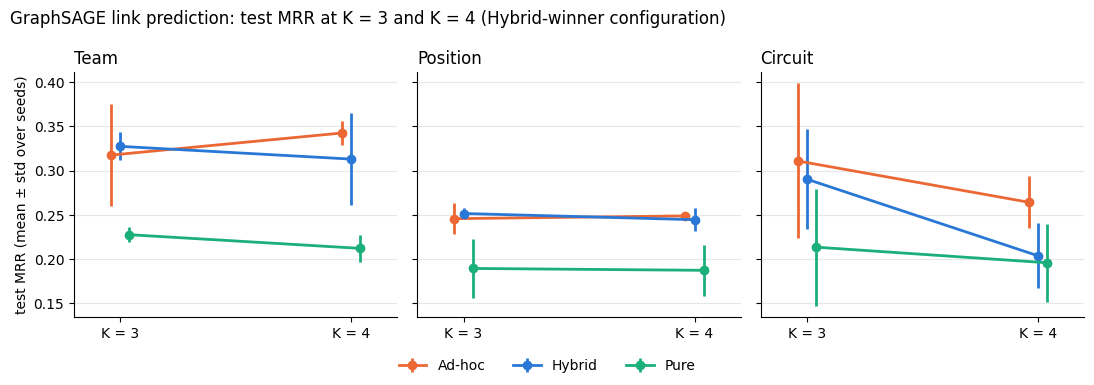

In [7]:
# Validated default categorical palette (dataviz skill), one fixed colour per KG.
colors = {"adhoc": "#eb6834", "hybrid_sulo": "#2a78d6", "pure_sulo": "#1baf7a"}
names = {"adhoc": "Ad-hoc", "hybrid_sulo": "Hybrid", "pure_sulo": "Pure"}
fig, axes = plt.subplots(1, len(TARGETS), figsize=(11, 3.8), sharey=True)
for ax, target in zip(axes, TARGETS):
    metric = f"test_{target}_mrr"
    for i, kg in enumerate(KGS):
        rows = summary.loc[[f"{kg}_K3", f"{kg}_K4"]]
        x = np.array([3, 4]) + (i - 1) * 0.04          # a small offset keeps equal points apart
        ax.errorbar(x, rows[f"{metric}_mean"], yerr=rows[f"{metric}_std"], color=colors[kg], marker="o",
                    markersize=6, linewidth=2, capsize=0, label=names[kg])
    ax.set_title(target.capitalize(), loc="left")
    ax.set_xticks([3, 4], ["K = 3", "K = 4"])
    ax.set_xlim(2.8, 4.2)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("test MRR (mean ± std over seeds)")
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, loc="lower center", ncol=3)
fig.suptitle("GraphSAGE link prediction: test MRR at K = 3 and K = 4 (Hybrid-winner configuration)", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(OUT_DIR / "depth_test_mrr.png", dpi=200)
plt.show()

## Limitation: runs ended by the epoch cap

A seed whose best epoch is ≥ `EPOCHS − PATIENCE` was cut off by the `EPOCHS` cap while possibly still
improving, so its score may be understated (the same limitation as in the main notebooks).

In [8]:
results[results["best_epoch"] >= EPOCHS - PATIENCE][["variant", "seed", "best_epoch", "val_mrr", "test_mrr",
                                                        *(f"test_{t}_mrr" for t in TARGETS)]]

,variant,seed,best_epoch,val_mrr,test_mrr,test_team_mrr,test_position_mrr,test_circuit_mrr
0,hybrid_sulo_K3,0,388,0.296047,0.282024,0.315511,0.245694,0.298940
1,hybrid_sulo_K3,1,389,0.308635,0.299252,0.340377,0.258922,0.224886
2,hybrid_sulo_K3,2,397,0.304453,0.296870,0.337487,0.252370,0.327061
3,hybrid_sulo_K3,3,393,0.289327,0.278145,0.305588,0.245317,0.359842
4,hybrid_sulo_K3,4,385,0.306246,0.295976,0.338204,0.253634,0.240272
5,adhoc_K3,0,390,0.303748,0.295691,0.334473,0.253140,0.325876
6,adhoc_K3,1,395,0.304631,0.295646,0.335274,0.250964,0.353202
8,adhoc_K3,3,397,0.318673,0.309610,0.357398,0.254518,0.405817
9,adhoc_K3,4,393,0.309790,0.300942,0.344845,0.254374,0.299546
13,pure_sulo_K3,3,378,0.237241,0.234588,0.238282,0.227283,0.309662


## Width check

Ad-hoc and Hybrid at Ad-hoc's tuned configuration (its phase-4 winner), same protocol. Only the width may differ
from the Hybrid winner used above; the cell asserts that the depth, lr and wd are equal. The table compares the
Hybrid − Ad-hoc gap at the main runs' own winners, at the shared Hybrid winner (the ablation's controls) and at the
shared Ad-hoc winner.

In [9]:
adhoc_winner = phase4_winner("adhoc")
W_DIM, W_DEPTH = int(adhoc_winner["hidden_dim"]), int(adhoc_winner["layers"])
assert (W_DEPTH, float(adhoc_winner["lr"]), float(adhoc_winner["weight_decay"])) == (3, LR, WD), "not only the width differs"
print(f"Ad-hoc winner: dim {W_DIM} (Hybrid winner: {DIM}), layers {W_DEPTH}, lr {LR}, wd {WD}")

width_csv = OUT_DIR / "width.csv"
for kg in ("adhoc", "hybrid_sulo"):
    run_lp_ablation_variant(
        model_factory(lp_data[kg]), lp_data[kg], kg, [W_DIM] * (W_DEPTH - 1), BASES, LR, WD,
        epochs=EPOCHS, patience=PATIENCE, start_from_epoch=START_FROM_EPOCH,
        disjoint_ratio=DISJOINT_TRAIN_RATIO, seeds=FINAL_SEEDS,
        save_dir=f"{OUT_DIR / 'checkpoints' / 'width'}/", csv_path=width_csv,
    )
    cleanup()

width = pd.read_csv(width_csv)
assert (width["status"] == "ok").all() and len(width) == 2 * len(FINAL_SEEDS)
assert same_config(width, W_DIM, W_DEPTH)

test_mrr = LP_ABLATION_METRICS[1:]
settings = {
    "main runs (own winners, train+val retrain)": {
        kg: pd.read_csv(MAIN_DIR / f"{kg}_sequential_tuning_results.csv")
              .query("phase == '4_Final_Test_Evaluation'")[test_mrr].mean() for kg in ("adhoc", "hybrid_sulo")},
    f"shared Hybrid winner ({DIM}-d, the ablation's controls)":
        {kg: reused[reused["variant"] == kg][test_mrr].mean() for kg in ("adhoc", "hybrid_sulo")},
    f"shared Ad-hoc winner ({W_DIM}-d)": {kg: width[width["variant"] == kg][test_mrr].mean() for kg in ("adhoc", "hybrid_sulo")},
}
table = {}
for setting, by_kg in settings.items():
    table[(setting, "Ad-hoc")] = by_kg["adhoc"]
    table[(setting, "Hybrid")] = by_kg["hybrid_sulo"]
    table[(setting, "Hybrid − Ad-hoc")] = by_kg["hybrid_sulo"] - by_kg["adhoc"]
width_table = pd.DataFrame(table).T
width_table.round(4).to_csv(OUT_DIR / "width_summary.csv")
width_table.round(4)

Ad-hoc winner: dim 256 (Hybrid winner: 64), layers 3, lr 0.005, wd 0.0

=== LP ablation adhoc | seed 0 ===
Epoch 000 | Train Loss: 4.3900 | Val MRR: 0.1857 (team 0.2129, position 0.1588, circuit 0.1471) | Grad Norm: 0.9107
Epoch 001 | Train Loss: 4.8268 | Val MRR: 0.1115 (team 0.0651, position 0.1584, circuit 0.1552) | Grad Norm: 15.4999
Epoch 002 | Train Loss: 4.5308 | Val MRR: 0.1535 (team 0.1502, position 0.1569, circuit 0.1568) | Grad Norm: 4.4498
Epoch 003 | Train Loss: 4.3125 | Val MRR: 0.1737 (team 0.1901, position 0.1572, circuit 0.1561) | Grad Norm: 1.7643
Epoch 004 | Train Loss: 4.1595 | Val MRR: 0.1546 (team 0.1522, position 0.1572, circuit 0.1561) | Grad Norm: 1.4936
Epoch 005 | Train Loss: 4.0332 | Val MRR: 0.1547 (team 0.1522, position 0.1572, circuit 0.1568) | Grad Norm: 1.4742
Epoch 006 | Train Loss: 3.9532 | Val MRR: 0.1556 (team 0.1522, position 0.1586, circuit 0.1660) | Grad Norm: 1.5780
Epoch 007 | Train Loss: 3.9728 | Val MRR: 0.1554 (team 0.1525, position 0.1586, 

test_mrr  \
main runs (own winners, train+val retrain)         Ad-hoc             0.3344   
                                                   Hybrid             0.2921   
                                                   Hybrid − Ad-hoc   -0.0423   
shared Hybrid winner (64-d, the ablation's cont... Ad-hoc             0.2831   
                                                   Hybrid             0.2905   
                                                   Hybrid − Ad-hoc    0.0073   
shared Ad-hoc winner (256-d)                       Ad-hoc             0.3069   
                                                   Hybrid             0.3343   
                                                   Hybrid − Ad-hoc    0.0274   

                                                                    test_team_mrr  \
main runs (own winners, train+val retrain)         Ad-hoc                  0.3973   
                                                   Hybrid                  0.3291   
                                                   Hybrid − Ad-hoc        -0.0683   
shared Hybrid winner (64-d, the ablation's cont... Ad-hoc                  0.3175   
                                                   Hybrid                  0.3274   
                                                   Hybrid − Ad-hoc         0.0099   
shared Ad-hoc winner (256-d)                       Ad-hoc                  0.3544   
                                                   Hybrid                  0.3998   
                                                   Hybrid − Ad-hoc         0.0454   

                                                                    test_position_mrr  \
main runs (own winners, train+val retrain)         Ad-hoc                      0.2576   
                                                   Hybrid                      0.2508   
                                                   Hybrid − Ad-hoc            -0.0068   
shared Hybrid winner (64-d, the ablation's cont... Ad-hoc                      0.2453   
                                                   Hybrid                      0.2512   
                                                   Hybrid − Ad-hoc             0.0058   
shared Ad-hoc winner (256-d)                       Ad-hoc                      0.2472   
                                                   Hybrid                      0.2519   
                                                   Hybrid − Ad-hoc             0.0047   

                                                                    test_circuit_mrr  
main runs (own winners, train+val retrain)         Ad-hoc                     0.5550  
                                                   Hybrid                     0.3376  
                                                   Hybrid − Ad-hoc           -0.2174  
shared Hybrid winner (64-d, the ablation's cont... Ad-hoc                     0.3109  
                                                   Hybrid                     0.2902  
                                                   Hybrid − Ad-hoc           -0.0207  
shared Ad-hoc winner (256-d)                       Ad-hoc                     0.5117  
                                                   Hybrid                     0.6218  
                                                   Hybrid − Ad-hoc            0.1101

In [10]:
width.groupby("variant")[test_mrr].agg(["mean", "std"]).round(4)

test_mrr         test_team_mrr         test_position_mrr          \
                mean     std          mean     std              mean     std   
variant                                                                        
adhoc         0.3069  0.0524        0.3544  0.0801            0.2472  0.0168   
hybrid_sulo   0.3343  0.0156        0.3998  0.0273            0.2519  0.0050   

            test_circuit_mrr          
                        mean     std  
variant                               
adhoc                 0.5117  0.2026  
hybrid_sulo           0.6218  0.0697